# ES 673 Assignment 4 - Q2: SNN on Poisson encoded MNIST

784 Poisson inputs -> LIF hidden layer (Brian2) -> logistic regression on spike counts.

Tweak tried: homeostatic firing-rate regulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from brian2 import *
from torchvision import datasets
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

prefs.codegen.target = 'cython'
BrianLogger.log_level_error()
seed(0)

In [2]:
train_set = datasets.MNIST('data', train=True, download=True)
test_set = datasets.MNIST('data', train=False, download=True)

N_train, N_test = 6000, 1000
X_train = train_set.data[:N_train].reshape(N_train, -1).numpy() / 255.0
y_train = train_set.targets[:N_train].numpy()
X_test = test_set.data[:N_test].reshape(N_test, -1).numpy() / 255.0
y_test = test_set.targets[:N_test].numpy()
print(X_train.shape, X_test.shape)

(6000, 784) (1000, 784)


## Parameters

In [3]:
N_in = 784
N_hid = 400
T_enc = 100*ms
T = float(T_enc / second)
max_rate = 100*Hz   # pixel = 1 -> 100 Hz

tau_m = 20*ms
v_rest = -65*mV
v_reset = -65*mV
v_th = -52*mV
t_ref = 2*ms

p_conn = 0.2
w_unit = 0.2*mV / p_conn   # keeps the mean total input the same for any p

synapses: 62814 | inputs per hidden neuron: 157.0


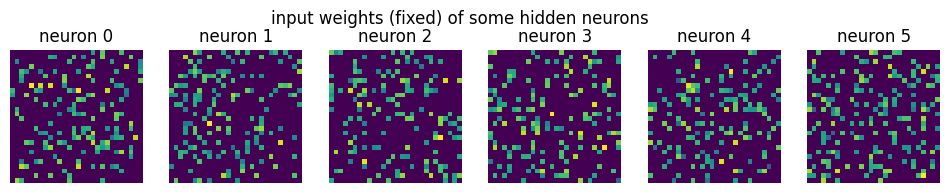

In [4]:
def make_weights(p):
    rng = np.random.default_rng(0)
    conn = rng.random((N_in, N_hid)) < p
    pre, post = np.nonzero(conn)
    W = np.clip(rng.normal(0.5, 0.1, (N_in, N_hid)), 0, None) * conn
    return pre, post, W

pre, post, W = make_weights(p_conn)
print('synapses:', len(pre), '| inputs per hidden neuron: %.1f' % (len(pre) / N_hid))

fig, ax = plt.subplots(1, 6, figsize=(12, 2.2))
for k in range(6):
    ax[k].imshow(W[:, k].reshape(28, 28))
    ax[k].set_title(f'neuron {k}')
    ax[k].axis('off')
plt.suptitle('input weights (fixed) of some hidden neurons')
plt.show()

## Network

Hidden neurons are LIF with refractoriness and current-based (delta) excitatory synapses. `theta` is an extra threshold term used only for the homeostasis part; in the baseline `eta = 0` so `theta` stays 0.
All images are run back to back using a `TimedArray` for the input rates, and `v` is reset to `v_rest` at the start of every image.

In [5]:
eqs = '''
dv/dt = (v_rest - v) / tau_m : volt (unless refractory)
dtheta/dt = -eta * r_target : volt
'''

def simulate(X, theta0=None, eta=0*mV, r_target=20*Hz, n_record=0,
             tau_m=tau_m, conn=(pre, post, W), w_unit=w_unit):
    start_scope()
    stim = TimedArray(X * max_rate, dt=T_enc)
    inp = PoissonGroup(N_in, rates='stim(t, i)')

    hid = NeuronGroup(N_hid, eqs, threshold='v > v_th + theta', reset='v = v_reset; theta += eta',
                      refractory=t_ref, method='euler')
    hid.v = v_rest
    if theta0 is not None:
        hid.theta = theta0 * mV
    hid.run_regularly('v = v_rest', dt=T_enc)

    syn = Synapses(inp, hid, 'w : volt', on_pre='v_post += w')
    i_pre, j_post, Wc = conn
    syn.connect(i=i_pre, j=j_post)
    syn.w = Wc[i_pre, j_post] * w_unit

    spk = SpikeMonitor(hid)
    th_mon = StateMonitor(hid, 'theta', record=True, dt=10*T_enc)
    if n_record > 0:
        in_spk = SpikeMonitor(inp)
        v_mon = StateMonitor(hid, 'v', record=range(n_record))

    run(len(X) * T_enc)

    counts = np.zeros((len(X), N_hid))
    first = np.full((len(X), N_hid), np.nan)   # first spike time in each image (ms)
    img = (spk.t / T_enc).astype(int)
    idx = np.array(spk.i)
    np.add.at(counts, (img, idx), 1)
    np.fmin.at(first, (img, idx), (spk.t - img * T_enc) / ms)

    out = {'counts': counts, 'first': first, 'theta': hid.theta[:] / mV,
           'theta_t': th_mon.t / second, 'theta_hist': th_mon.theta / mV}
    if n_record > 0:
        out.update(spk_t=spk.t / ms, spk_i=np.array(spk.i), in_t=in_spk.t / ms, in_i=np.array(in_spk.i),
                   v_t=v_mon.t / ms, v=v_mon.v / mV)
    return out


def readout(c_train, c_test):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    clf.fit(c_train, y_train)
    return clf, clf.score(c_test, y_test)

### Example: 3 test images

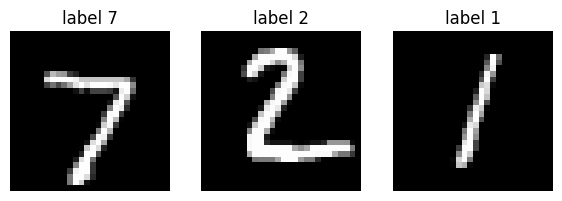

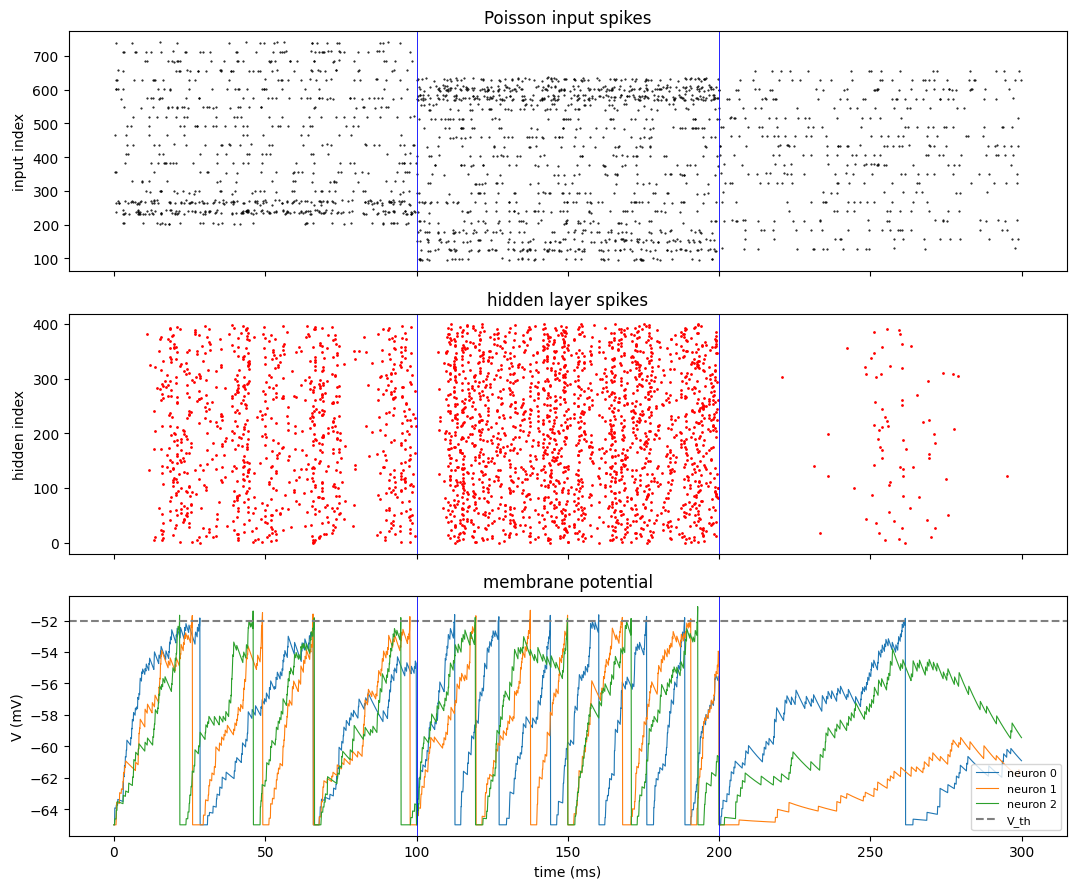

In [6]:
demo = simulate(X_test[:3], n_record=5)

fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))
for k in range(3):
    ax[k].imshow(X_test[k].reshape(28, 28), cmap='gray')
    ax[k].set_title(f'label {y_test[k]}')
    ax[k].axis('off')
plt.show()

fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
ax[0].plot(demo['in_t'], demo['in_i'], '.k', ms=1)
ax[0].set_ylabel('input index')
ax[0].set_title('Poisson input spikes')
ax[1].plot(demo['spk_t'], demo['spk_i'], '.r', ms=2)
ax[1].set_ylabel('hidden index')
ax[1].set_title('hidden layer spikes')
for k in range(3):
    ax[2].plot(demo['v_t'], demo['v'][k], lw=0.8, label=f'neuron {k}')
ax[2].axhline(v_th / mV, ls='--', c='gray', label='V_th')
ax[2].set_ylabel('V (mV)')
ax[2].set_xlabel('time (ms)')
ax[2].set_title('membrane potential')
ax[2].legend(loc='lower right', fontsize=8)
for a in ax:
    for b in (1, 2):
        a.axvline(b * T_enc / ms, c='b', lw=0.6)
plt.tight_layout()
plt.show()

## Baseline

In [7]:
%%time
base_tr = simulate(X_train)
base_te = simulate(X_test)
base_train, base_test = base_tr['counts'], base_te['counts']
clf_base, acc_base = readout(base_train, base_test)
print('baseline test accuracy:', acc_base)

baseline test accuracy: 0.824
CPU times: user 14min 8s, sys: 365 ms, total: 14min 8s
Wall time: 4min 20s


In [8]:
pix = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)
print('reference - logistic regression on raw pixels:', pix.score(X_test, y_test))

reference - logistic regression on raw pixels: 0.873


mean rate 40.4 Hz | min 12.9 | max 61.1 | silent 0
hidden spikes per image: 1615.4


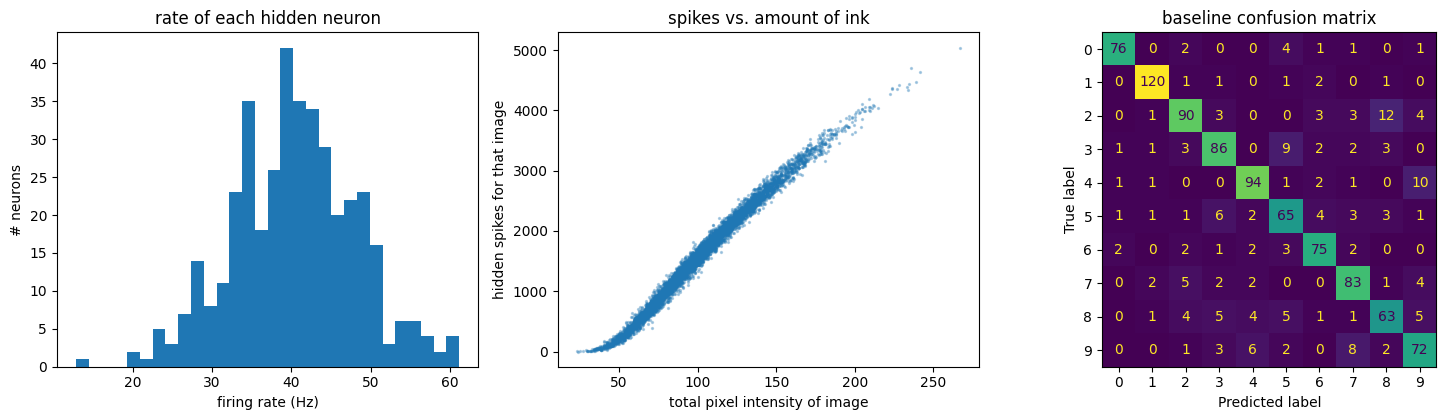

In [9]:
rate_base = base_train.mean(0) / T
print('mean rate %.1f Hz | min %.1f | max %.1f | silent %d' % (rate_base.mean(), rate_base.min(), rate_base.max(), (rate_base == 0).sum()))
print('hidden spikes per image: %.1f' % base_train.sum(1).mean())

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].hist(rate_base, bins=30)
ax[0].set_xlabel('firing rate (Hz)')
ax[0].set_ylabel('# neurons')
ax[0].set_title('rate of each hidden neuron')
ax[1].scatter(X_train.sum(1), base_train.sum(1), s=2, alpha=0.3)
ax[1].set_xlabel('total pixel intensity of image')
ax[1].set_ylabel('hidden spikes for that image')
ax[1].set_title('spikes vs. amount of ink')
ConfusionMatrixDisplay(confusion_matrix(y_test, clf_base.predict(base_test))).plot(ax=ax[2], colorbar=False)
ax[2].set_title('baseline confusion matrix')
plt.tight_layout()
plt.show()

## Tweak: homeostatic firing-rate regulation

Every hidden neuron gets its own threshold shift `theta`:
- on a spike: `theta += eta`
- otherwise: `dtheta/dt = -eta * r_target`

so on average `dtheta/dt = eta * (r - r_target)`. Neurons firing above the target get a higher threshold, neurons below get a lower one.
`theta` is adapted on 2000 training images (no labels used), then frozen (`eta = 0`) and the same feature extraction + readout as the baseline is repeated.
Targets: 20 Hz (about half of the baseline rate) and 40 Hz (about the baseline rate).

In [10]:
%%time
eta = 0.01*mV
homeo = {}
for r_t in [20, 40]:
    adapt = simulate(X_train[:2000], eta=eta, r_target=r_t*Hz)
    c_train = simulate(X_train, theta0=adapt['theta'])['counts']
    c_test = simulate(X_test, theta0=adapt['theta'])['counts']
    clf, acc = readout(c_train, c_test)
    homeo[r_t] = dict(adapt=adapt, train=c_train, test=c_test, clf=clf, acc=acc)
    print(f'target {r_t} Hz: test accuracy {acc:.4f}, mean rate {c_train.mean() / T:.1f} Hz')

target 20 Hz: test accuracy 0.7910, mean rate 19.9 Hz


target 40 Hz: test accuracy 0.8270, mean rate 39.0 Hz
CPU times: user 31min 18s, sys: 697 ms, total: 31min 19s
Wall time: 10min 43s


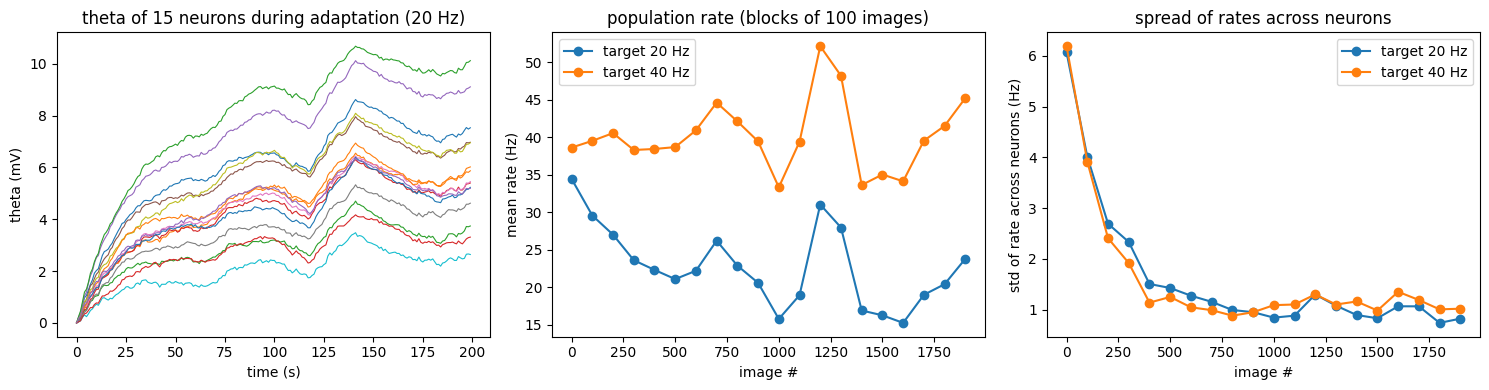

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
a = homeo[20]['adapt']
ax[0].plot(a['theta_t'], a['theta_hist'][:15].T, lw=0.8)
ax[0].set_xlabel('time (s)')
ax[0].set_ylabel('theta (mV)')
ax[0].set_title('theta of 15 neurons during adaptation (20 Hz)')

for r_t, h in homeo.items():
    c = h['adapt']['counts'].reshape(20, 100, N_hid).mean(1) / T
    ax[1].plot(np.arange(20) * 100, c.mean(1), 'o-', label=f'target {r_t} Hz')
    ax[2].plot(np.arange(20) * 100, c.std(1), 'o-', label=f'target {r_t} Hz')
ax[1].set_xlabel('image #')
ax[1].set_ylabel('mean rate (Hz)')
ax[1].set_title('population rate (blocks of 100 images)')
ax[1].legend()
ax[2].set_xlabel('image #')
ax[2].set_ylabel('std of rate across neurons (Hz)')
ax[2].set_title('spread of rates across neurons')
ax[2].legend()
plt.tight_layout()
plt.show()

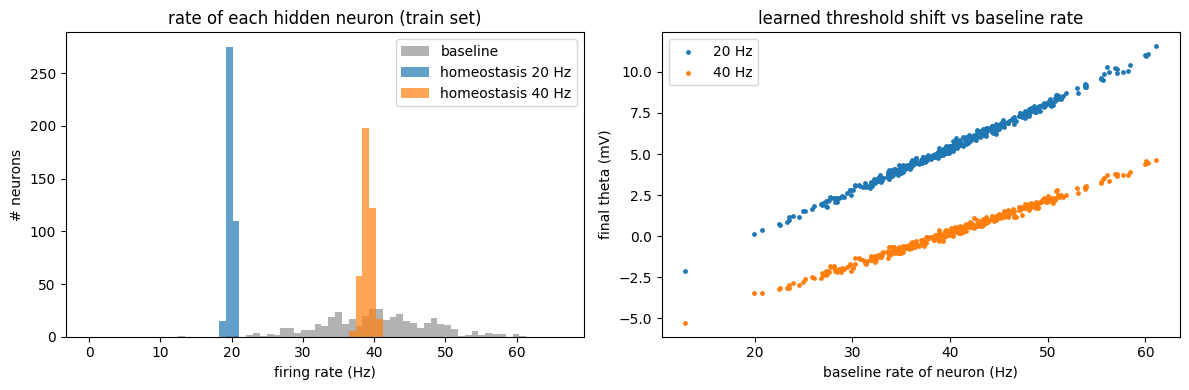

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, rate_base.max() + 5, 70)
ax[0].hist(rate_base, bins=bins, alpha=0.6, color='gray', label='baseline')
for r_t, h in homeo.items():
    ax[0].hist(h['train'].mean(0) / T, bins=bins, alpha=0.7, label=f'homeostasis {r_t} Hz')
ax[0].set_xlabel('firing rate (Hz)')
ax[0].set_ylabel('# neurons')
ax[0].legend()
ax[0].set_title('rate of each hidden neuron (train set)')

for r_t, h in homeo.items():
    ax[1].scatter(rate_base, h['adapt']['theta'], s=6, label=f'{r_t} Hz')
ax[1].set_xlabel('baseline rate of neuron (Hz)')
ax[1].set_ylabel('final theta (mV)')
ax[1].set_title('learned threshold shift vs baseline rate')
ax[1].legend()
plt.tight_layout()
plt.show()

## Comparison

model                 test acc   rate (Hz)  rate std  spikes/img
baseline                0.8240        40.4       7.8      1615.4
homeostasis 20 Hz       0.7910        19.9       0.4       794.7
homeostasis 40 Hz       0.8270        39.0       0.7      1560.2


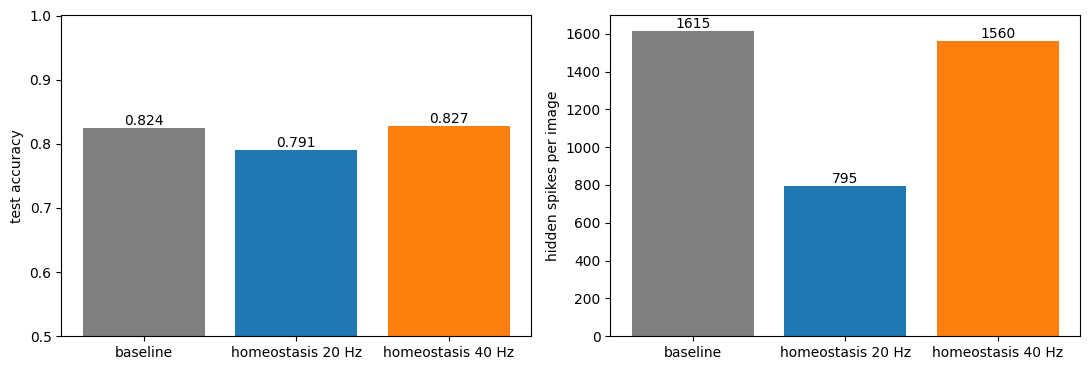

In [13]:
rows = [('baseline', acc_base, base_train)] + [(f'homeostasis {r_t} Hz', h['acc'], h['train']) for r_t, h in homeo.items()]
print(f"{'model':<20}{'test acc':>10}{'rate (Hz)':>12}{'rate std':>10}{'spikes/img':>12}")
for name, acc, c in rows:
    r = c.mean(0) / T
    print(f'{name:<20}{acc:>10.4f}{r.mean():>12.1f}{r.std():>10.1f}{c.sum(1).mean():>12.1f}')

names = [r[0] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
b = ax[0].bar(names, [r[1] for r in rows], color=['gray', 'C0', 'C1'])
ax[0].bar_label(b, fmt='%.3f')
ax[0].set_ylim(0.5, 1)
ax[0].set_ylabel('test accuracy')
b = ax[1].bar(names, [r[2].sum(1).mean() for r in rows], color=['gray', 'C0', 'C1'])
ax[1].bar_label(b, fmt='%.0f')
ax[1].set_ylabel('hidden spikes per image')
plt.tight_layout()
plt.show()

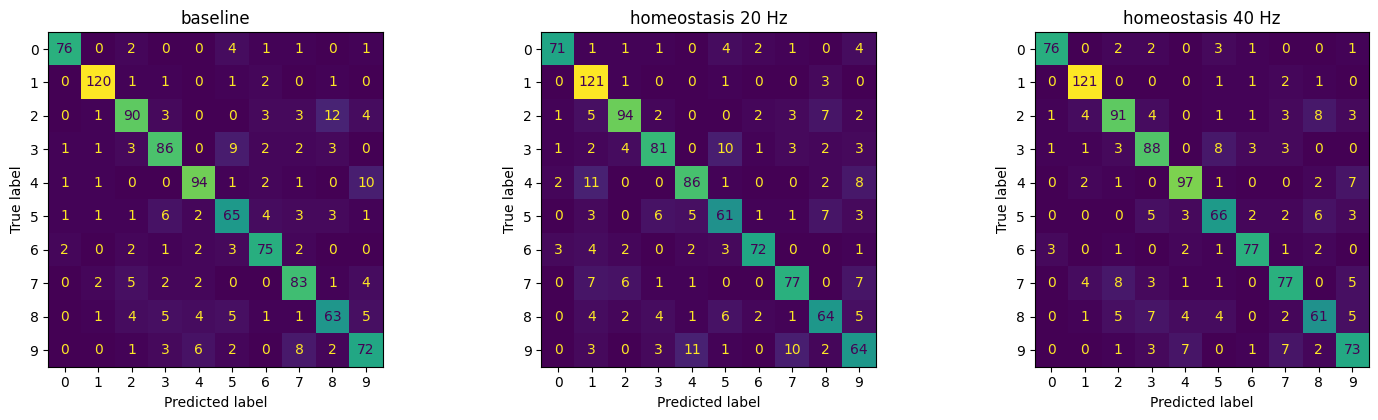

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
models = [('baseline', clf_base, base_test)] + [(f'homeostasis {r_t} Hz', h['clf'], h['test']) for r_t, h in homeo.items()]
for k, (name, clf, c) in enumerate(models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, clf.predict(c))).plot(ax=ax[k], colorbar=False)
    ax[k].set_title(name)
plt.tight_layout()
plt.show()

## Extra 1: changing the membrane time constant

Same weights and inputs, only `tau_m` changes (5, 10, 20, 50 ms). 20 ms is the baseline run from above.

In [15]:
%%time
tau_res = {20: dict(train=base_train, test=base_test, first=base_te['first'], acc=acc_base)}
for tau in [5, 10, 50]:
    a = simulate(X_train, tau_m=tau*ms)
    b = simulate(X_test, tau_m=tau*ms)
    clf, acc = readout(a['counts'], b['counts'])
    tau_res[tau] = dict(train=a['counts'], test=b['counts'], first=b['first'], acc=acc)
    print(f'tau_m = {tau} ms: test accuracy {acc:.4f}, mean rate {a["counts"].mean() / T:.1f} Hz')
tau_res = dict(sorted(tau_res.items()))

tau_m = 5 ms: test accuracy 0.2900, mean rate 0.7 Hz


tau_m = 10 ms: test accuracy 0.7610, mean rate 16.5 Hz


tau_m = 50 ms: test accuracy 0.8360, mean rate 54.6 Hz
CPU times: user 40min 53s, sys: 3.3 s, total: 40min 56s
Wall time: 13min 11s


 tau_m  test acc  rate (Hz)  spikes/img  silent %  1st spike (ms)
     5    0.2900        0.7        27.1      97.5            44.1
    10    0.7610       16.5       660.1      55.5            35.5
    20    0.8240       40.4      1615.4      13.0            26.0
    50    0.8360       54.6      2185.7       1.5            20.1


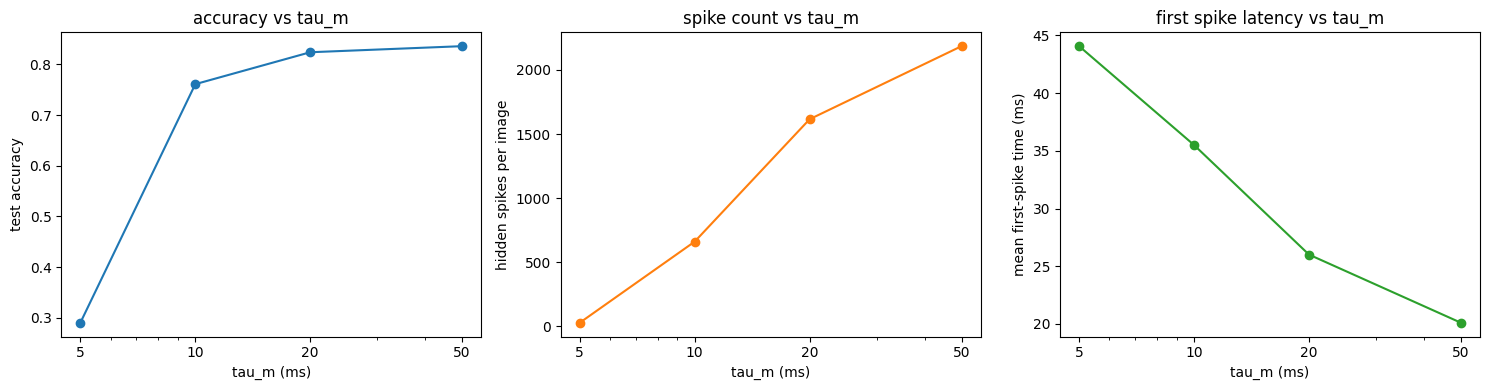

In [16]:
taus = list(tau_res)
print(f"{'tau_m':>6}{'test acc':>10}{'rate (Hz)':>11}{'spikes/img':>12}{'silent %':>10}{'1st spike (ms)':>16}")
for tau, r in tau_res.items():
    silent = 100 * (r['test'] == 0).mean()
    print(f"{tau:>6}{r['acc']:>10.4f}{r['train'].mean() / T:>11.1f}{r['train'].sum(1).mean():>12.1f}{silent:>10.1f}{np.nanmean(r['first']):>16.1f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(taus, [r['acc'] for r in tau_res.values()], 'o-')
ax[0].set_ylabel('test accuracy')
ax[0].set_title('accuracy vs tau_m')
ax[1].plot(taus, [r['train'].sum(1).mean() for r in tau_res.values()], 'o-', c='C1')
ax[1].set_ylabel('hidden spikes per image')
ax[1].set_title('spike count vs tau_m')
ax[2].plot(taus, [np.nanmean(r['first']) for r in tau_res.values()], 'o-', c='C2')
ax[2].set_ylabel('mean first-spike time (ms)')
ax[2].set_title('first spike latency vs tau_m')
for a in ax:
    a.set_xscale('log')
    a.set_xticks(taus, [str(t) for t in taus])
    a.set_xlabel('tau_m (ms)')
plt.tight_layout()
plt.show()

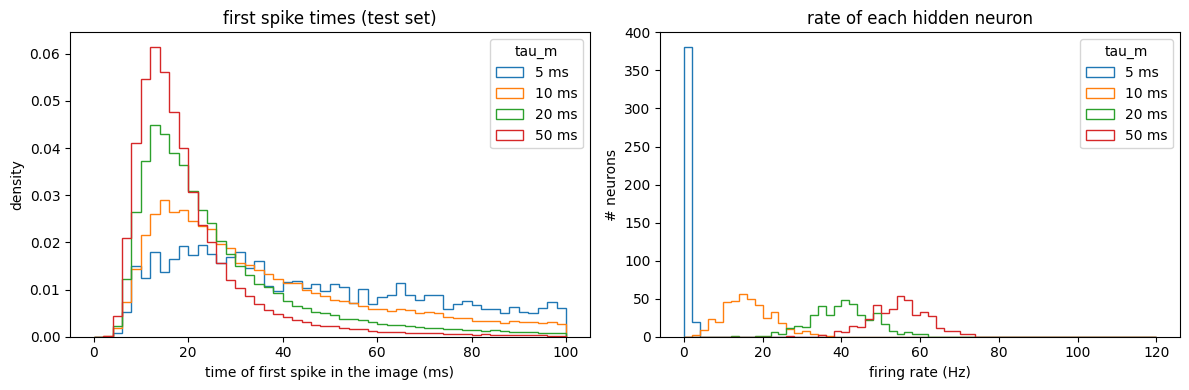

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for tau, r in tau_res.items():
    ax[0].hist(r['first'][~np.isnan(r['first'])], bins=np.arange(0, 101, 2), histtype='step', lw=1.5, density=True, label=f'{tau} ms')
    ax[1].hist(r['train'].mean(0) / T, bins=np.linspace(0, 120, 61), histtype='step', lw=1.5, label=f'{tau} ms')
ax[0].set_xlabel('time of first spike in the image (ms)')
ax[0].set_ylabel('density')
ax[0].set_title('first spike times (test set)')
ax[0].legend(title='tau_m')
ax[1].set_xlabel('firing rate (Hz)')
ax[1].set_ylabel('# neurons')
ax[1].set_title('rate of each hidden neuron')
ax[1].legend(title='tau_m')
plt.tight_layout()
plt.show()

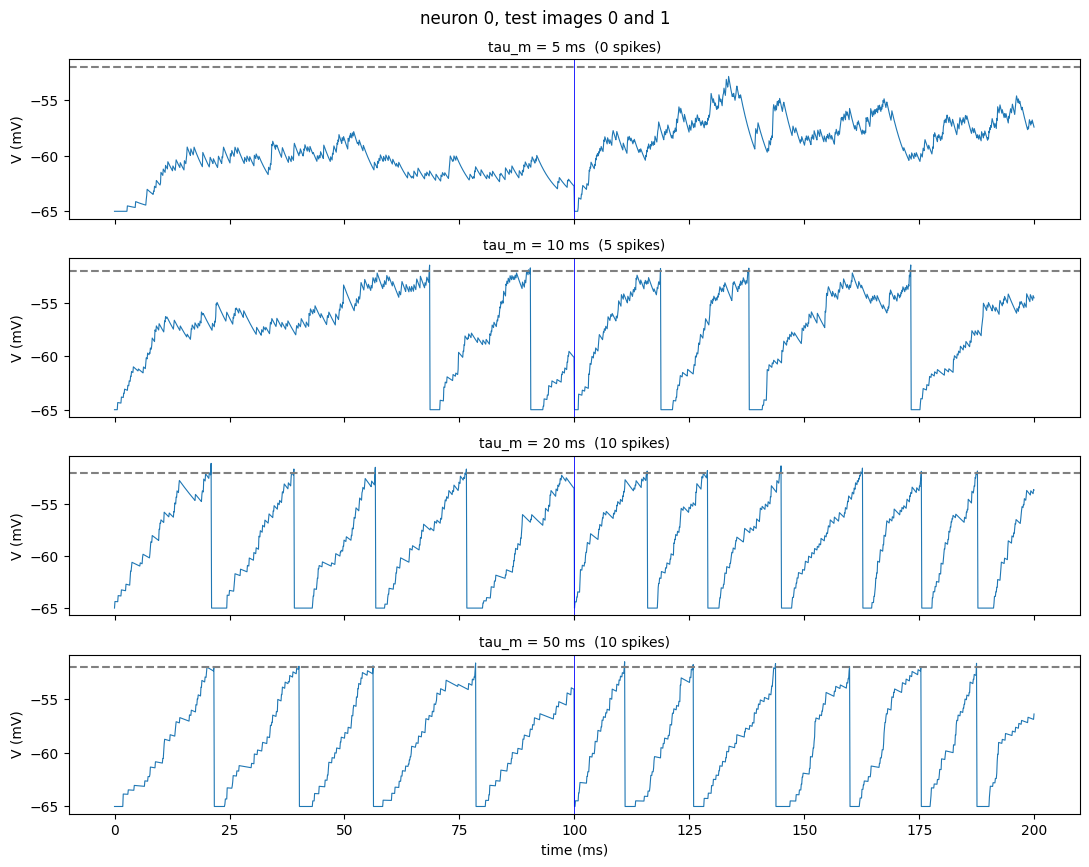

In [18]:
fig, ax = plt.subplots(len(taus), 1, figsize=(11, 2.2 * len(taus)), sharex=True)
for k, tau in enumerate(taus):
    d = simulate(X_test[:2], tau_m=tau*ms, n_record=1)
    ax[k].plot(d['v_t'], d['v'][0], lw=0.8)
    ax[k].axhline(v_th / mV, ls='--', c='gray')
    ax[k].axvline(T_enc / ms, c='b', lw=0.6)
    ax[k].set_ylabel('V (mV)')
    ax[k].set_title(f'tau_m = {tau} ms  ({(d["spk_i"] == 0).sum()} spikes)', fontsize=10)
ax[-1].set_xlabel('time (ms)')
plt.suptitle('neuron 0, test images 0 and 1')
plt.tight_layout()
plt.show()

## Extra 2: sparse connectivity

Connection probability 1.0 (dense), 0.2 (baseline) and 0.05. `w_unit = 0.2 mV / p`, so every case gets the same mean input and only the number of inputs per neuron changes.

In [19]:
%%time
conn_res = {0.2: dict(conn=(pre, post, W), train=base_train, test=base_test, clf=clf_base, acc=acc_base)}
for p in [1.0, 0.05]:
    c = make_weights(p)
    a = simulate(X_train, conn=c, w_unit=0.2*mV / p)['counts']
    b = simulate(X_test, conn=c, w_unit=0.2*mV / p)['counts']
    clf, acc = readout(a, b)
    conn_res[p] = dict(conn=c, train=a, test=b, clf=clf, acc=acc)
    print(f'p = {p}: test accuracy {acc:.4f}, mean rate {a.mean() / T:.1f} Hz')
conn_res = dict(sorted(conn_res.items(), reverse=True))

p = 1.0: test accuracy 0.5630, mean rate 39.3 Hz


p = 0.05: test accuracy 0.8390, mean rate 41.9 Hz
CPU times: user 40min 25s, sys: 2.15 s, total: 40min 27s
Wall time: 9min 27s


     p  inputs/neuron  test acc  rate (Hz)  rate std  spikes/img
   1.0          784.0    0.5630       39.3       0.9      1570.0
   0.2          157.0    0.8240       40.4       7.8      1615.4
  0.05           39.1    0.8390       41.9      14.7      1675.9


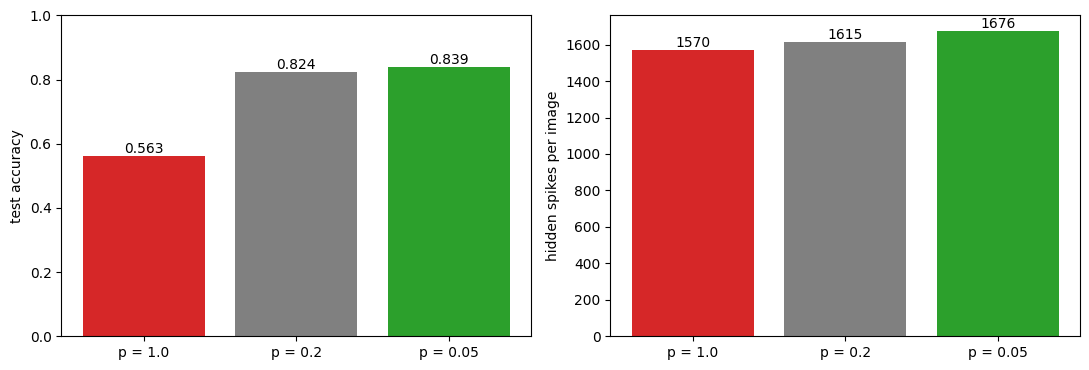

In [20]:
print(f"{'p':>6}{'inputs/neuron':>15}{'test acc':>10}{'rate (Hz)':>11}{'rate std':>10}{'spikes/img':>12}")
for p, r in conn_res.items():
    rate = r['train'].mean(0) / T
    print(f"{p:>6}{len(r['conn'][0]) / N_hid:>15.1f}{r['acc']:>10.4f}{rate.mean():>11.1f}{rate.std():>10.1f}{r['train'].sum(1).mean():>12.1f}")

labels = [f'p = {p}' for p in conn_res]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
b = ax[0].bar(labels, [r['acc'] for r in conn_res.values()], color=['C3', 'gray', 'C2'])
ax[0].bar_label(b, fmt='%.3f')
ax[0].set_ylim(0, 1)
ax[0].set_ylabel('test accuracy')
b = ax[1].bar(labels, [r['train'].sum(1).mean() for r in conn_res.values()], color=['C3', 'gray', 'C2'])
ax[1].bar_label(b, fmt='%.0f')
ax[1].set_ylabel('hidden spikes per image')
plt.tight_layout()
plt.show()

Input weights are fixed (no learning), so the initial filters are also the final ones. The second figure projects the trained readout back to pixel space (`W @ readout weights`) to show what each digit class looks for.

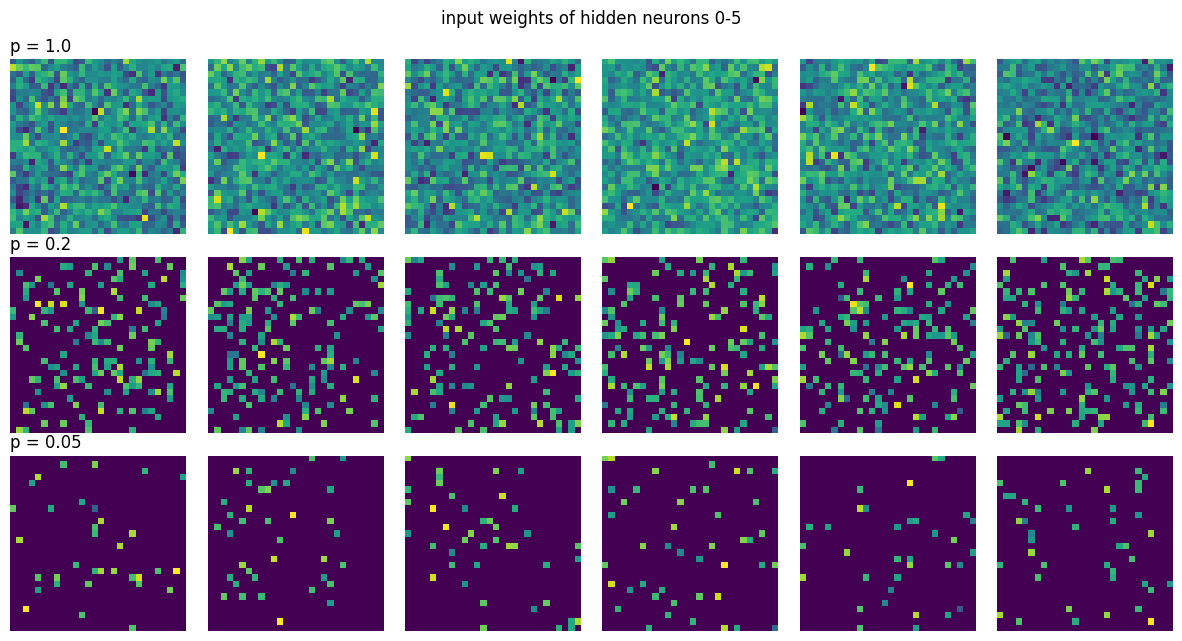

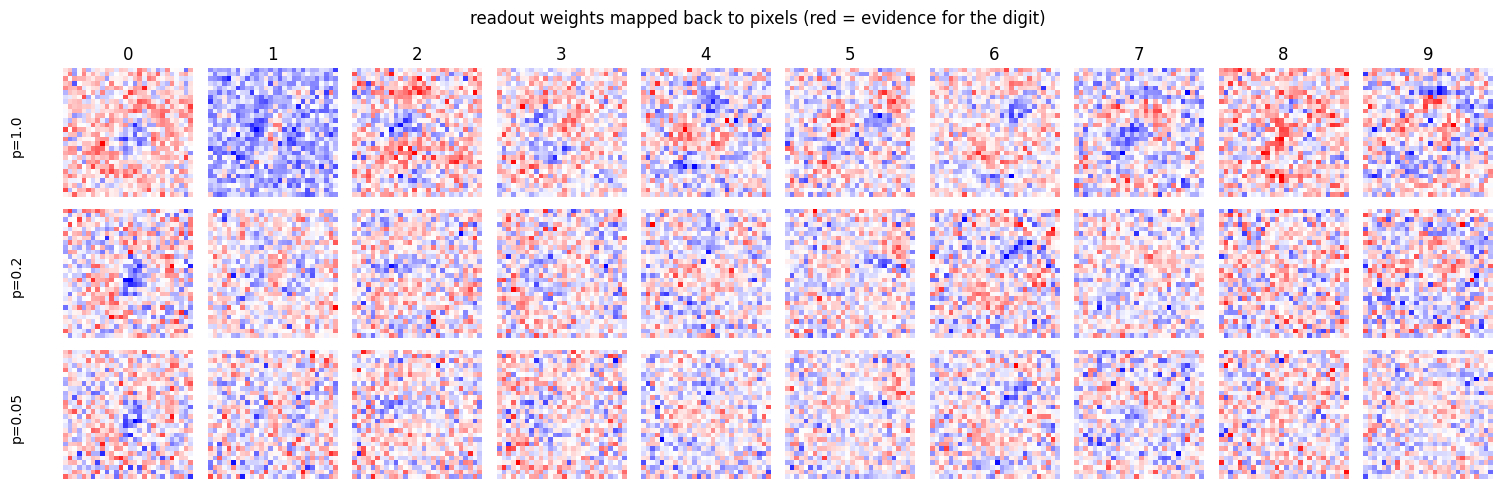

In [21]:
fig, ax = plt.subplots(3, 6, figsize=(12, 6.5))
for row, (p, r) in enumerate(conn_res.items()):
    Wc = r['conn'][2]
    for k in range(6):
        ax[row, k].imshow(Wc[:, k].reshape(28, 28))
        ax[row, k].axis('off')
    ax[row, 0].set_title(f'p = {p}', loc='left')
plt.suptitle('input weights of hidden neurons 0-5')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(3, 10, figsize=(15, 5))
for row, (p, r) in enumerate(conn_res.items()):
    lr = r['clf'].named_steps['logisticregression']
    sc = r['clf'].named_steps['standardscaler']
    filt = r['conn'][2] @ (lr.coef_ / sc.scale_).T
    for d in range(10):
        ax[row, d].imshow(filt[:, d].reshape(28, 28), cmap='bwr', vmin=-np.abs(filt[:, d]).max(), vmax=np.abs(filt[:, d]).max())
        ax[row, d].axis('off')
        if row == 0:
            ax[row, d].set_title(str(d))
    ax[row, 0].text(-12, 14, f'p={p}', rotation=90, va='center')
plt.suptitle('readout weights mapped back to pixels (red = evidence for the digit)')
plt.tight_layout()
plt.show()

## Observations